# Partie 2 : transfer learning et choix du modèle

Au lieu de partir de zéro, on part de réseaux déjà entraînés sur ImageNet et on les adapte à nos feuilles de tomate :

- 2.1 deux réseaux : MobileNetV3-Large (léger) et ResNet-50 (lourd) ;
- 2.2 trois façons de les adapter sur MobileNetV3 ;
- 2.3 précision, taille et temps de réponse de chaque modèle ;
- 2.4 le front de Pareto précision / temps de réponse ;
- 2.5 quel modèle mettre sur un smartphone d'entrée de gamme.

À la fin, on réentraîne le modèle choisi sans la maladie M. C'est ce classifieur qui sert en partie 4. Les images sont en 224×224.

- On ajoute le dossier du projet au chemin de Python pour pouvoir importer notre code (`src/`).
- `config` contient les chemins, la maladie M choisie et le GPU utilisé.
- `set_seed(42)` fixe le hasard, pour retrouver les mêmes résultats à chaque exécution.
- La dernière ligne affiche la machine utilisée.

In [63]:
import sys
from pathlib import Path

# dossier du projet, pour pouvoir importer src/
sys.path.insert(0, str(Path.cwd().parent))   

from src import config as C
C.set_seed(42)
print(C.describe_env())

Python 3.12.10, torch 2.6.0+cu124, torchvision 0.21.0+cu124
Calcul sur : cuda
GPU : NVIDIA GeForce RTX 4080 Laptop GPU
CPU : 13th Gen Intel(R) Core(TM) i7-13650HX (20 coeurs logiques)


- Ici on normalise avec les valeurs d'ImageNet, parce que les réseaux pré-entraînés ont appris avec elles.
- 5 époques suffisent : grâce à ImageNet, le réseau sait déjà reconnaître les formes et les textures de base.
- Même perte pondérée que dans la partie 1.

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from src import data as D
from src.models import TLModel, tl_optimizer, CNNPlain, CNNRes
from src.train import fit, load_best, export_checkpoint
from src.metrics import (predict, clf_report, plot_confusion, plot_histories, count_params, model_size_mb,
                         measure_latency, upsert_summary, update_summary, savefig)

df = D.load_splits()
NORM = D.norm_stats("imagenet")
SIZE = C.TL_SIZE
EPOCHS = C.ep(5)
loaders = D.clf_loaders(df, D.CLASSES, SIZE, NORM, batch_size=64)
poids = D.class_weights(loaders["train"].dataset.labels, len(D.CLASSES)).to(C.DEVICE)
criterion = nn.CrossEntropyLoss(weight=poids)
NOMS = [D.short(c) for c in D.CLASSES]

## 2.1 Les deux réseaux

MobileNetV3-Large est le réseau léger (environ 4 M de paramètres avec notre couche de sortie). Il a été conçu pour les téléphones. Ses convolutions sont « séparables » : un petit filtre par canal, puis une convolution 1×1 qui mélange les canaux, ce qui demande beaucoup moins de calculs qu'une convolution normale. Il reprend aussi les blocs de MobileNetV2 (étroit, puis large, puis étroit, avec une sortie sans activation pour ne pas perdre d'information). Enfin, son architecture a été cherchée automatiquement en mesurant la vitesse réelle sur téléphone.

ResNet-50 est le réseau lourd (environ 25 M de paramètres). Il empile des blocs résiduels 1×1, 3×3, 1×1. C'est notre référence : précis, mais coûteux.

La question est simple : le petit réseau peut-il faire presque aussi bien que le gros ?

## 2.2 Trois façons d'adapter MobileNetV3

| Stratégie | Ce qu'on entraîne | Learning rate |
|---|---|---|
| (a) `frozen` | seulement la nouvelle couche de sortie | 0,001 |
| (b) `last_third` | la sortie + le dernier tiers du réseau | sortie 0,001, réseau 0,0001 |
| (c) `full` | tout le réseau | sortie 0,001, réseau 0,00001 |

Dans les parties gelées, la BatchNorm garde les valeurs apprises sur ImageNet.

- `LR` donne, pour chaque stratégie, le learning rate de la couche de sortie et celui du reste du réseau.
- `entrainer_tl` crée le modèle : `TLModel` charge les poids ImageNet, remplace la dernière couche par une couche à 10 sorties et gèle ce qu'il faut. `tl_optimizer` crée Adam avec un learning rate pour la sortie et un autre pour le réseau.
- On entraîne les 3 stratégies l'une après l'autre.

In [65]:
# learning rate de la tête et du backbone pour chaque stratégie
LR = {"frozen": (0.001, None),            # (a) backbone gelé : seule la tête apprend
      "last_third": (0.001, 0.0001),      # (b) dernier tiers dégelé
      "full": (0.001, 0.00001)}           # (c) tout dégelé, learning rate différencié

def entrainer_tl(nom, arch, strategie, classes, loaders, criterion):
    C.set_seed(42)
    model = TLModel(arch, len(classes), strategie).to(C.DEVICE)
    lr_tete, lr_backbone = LR[strategie]
    optimizer = tl_optimizer(model, lr_head=lr_tete, lr_backbone=lr_backbone)
    meta = {"arch": arch, "strategy": strategie, "classes": classes, "size": SIZE, "norm": NORM}
    historique = fit(model, loaders, EPOCHS, optimizer, criterion, nom, meta)
    return model, historique

modeles = {}
historiques = {}
for strategie in ["frozen", "last_third", "full"]:
    nom = "mobilenet_v3_large_" + strategie
    modeles[nom], historiques[nom] = entrainer_tl(nom, "mobilenet_v3_large", strategie, D.CLASSES, loaders, criterion)

Reprise depuis l'époque 5
Reprise depuis l'époque 5
Reprise depuis l'époque 5


- Courbes des 3 stratégies.
- Pour chacune : nombre de paramètres entraînés, meilleur F1 de validation et temps.
- La meilleure stratégie est choisie sur la validation, jamais sur le test.

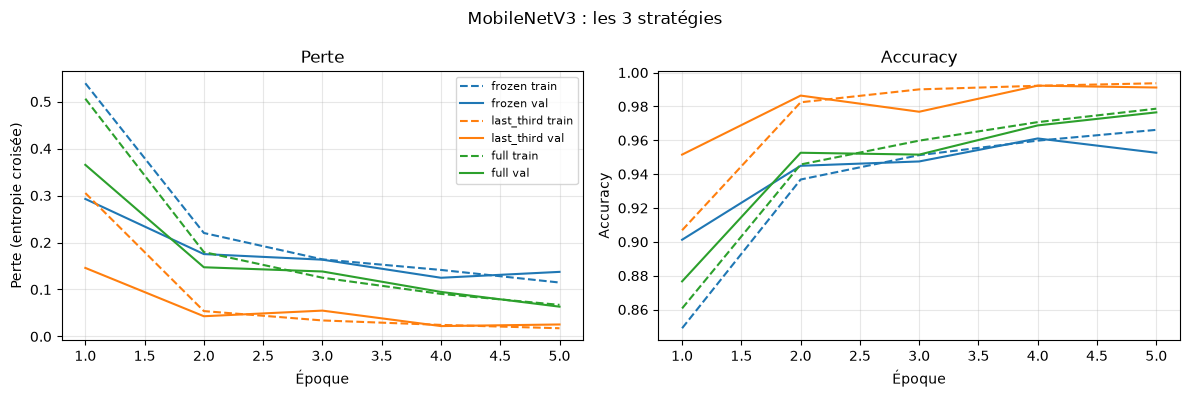

frozen : paramètres entraînés = 1242890 | meilleur F1 val = 0.9537 | temps = 103 s
last_third : paramètres entraînés = 4022898 | meilleur F1 val = 0.9916 | temps = 91 s
full : paramètres entraînés = 4214842 | meilleur F1 val = 0.9721 | temps = 116 s
Meilleure stratégie (sur la validation) : last_third


In [66]:
plot_histories({"frozen": historiques["mobilenet_v3_large_frozen"],
                "last_third": historiques["mobilenet_v3_large_last_third"],
                "full": historiques["mobilenet_v3_large_full"]},
               path=C.FIG_DIR / "02_strategies.png", title="MobileNetV3 : les 3 stratégies")

MEILLEURE = None
meilleur_f1 = 0
for strategie in ["frozen", "last_third", "full"]:
    nom = "mobilenet_v3_large_" + strategie
    h = historiques[nom]
    f1 = h["val_f1"].max()
    print(strategie, ": paramètres entraînés =", count_params(modeles[nom])[1],
          "| meilleur F1 val =", round(f1, 4), "| temps =", round(h["train_time_s"].iloc[-1]), "s")
    if f1 > meilleur_f1:
        meilleur_f1 = f1
        MEILLEURE = strategie
print("Meilleure stratégie (sur la validation) :", MEILLEURE)

### Ce qu'on observe

Avec le réseau gelé (a), le modèle apprend vite mais plafonne : 0,954 de F1 en validation et 0,948 sur le test. Ce que le réseau a appris sur ImageNet (contours, textures d'objets courants) ne suffit pas pour distinguer des taches de maladies qui se ressemblent. Target_Spot, par exemple, n'est reconnu qu'à 85 %.

Dégeler le dernier tiers (b) donne de loin le meilleur résultat : 0,992 de F1 en validation dès l'époque 4. Les dernières couches, qui repèrent les motifs les plus précis, s'adaptent aux maladies, tandis que les premières gardent ce qu'elles ont appris sur ImageNet. Il faut quand même préciser que chez MobileNetV3, ce dernier tiers contient 95 % des paramètres (4,02 M sur 4,21 M), parce que les dernières couches sont les plus larges.

Tout dégeler avec un learning rate de 0,00001 (c) fait mieux que (a) mais moins bien que (b), avec 0,972 de F1 en validation. La perte baisse encore à l'époque 5 : avec un pas aussi petit, 5 époques ne suffisent pas pour adapter tout le réseau.

Aucune des trois stratégies ne sur-apprend : les courbes de train et de validation restent proches.

- On entraîne ResNet-50 avec la meilleure stratégie trouvée sur MobileNetV3.
- On affiche ses courbes à côté de celles de MobileNetV3.

Reprise depuis l'époque 5


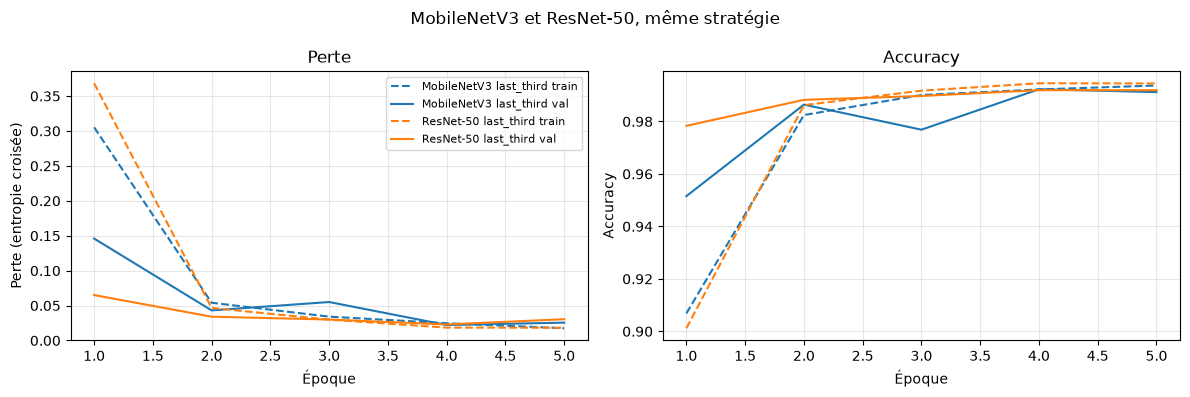

In [67]:
nom_lourd = "resnet50_" + MEILLEURE
modeles[nom_lourd], historiques[nom_lourd] = entrainer_tl(nom_lourd, "resnet50", MEILLEURE, D.CLASSES, loaders, criterion)

plot_histories({"MobileNetV3 " + MEILLEURE: historiques["mobilenet_v3_large_" + MEILLEURE],
                "ResNet-50 " + MEILLEURE: historiques[nom_lourd]},
               path=C.FIG_DIR / "02_mobilenet_resnet50.png", title="MobileNetV3 et ResNet-50, même stratégie")

## 2.3 Évaluation sur le test et temps de réponse

- Pour chaque modèle : on recharge les meilleurs poids, on prédit le test une seule fois, on calcule les métriques et on enregistre les prédictions.
- Matrices de confusion des 4 modèles, puis le rappel de chaque classe.

mobilenet_v3_large_frozen : accuracy 0.9567 | F1 macro 0.9479
mobilenet_v3_large_last_third : accuracy 0.996 | F1 macro 0.9955
mobilenet_v3_large_full : accuracy 0.982 | F1 macro 0.9778
resnet50_last_third : accuracy 0.9927 | F1 macro 0.9913


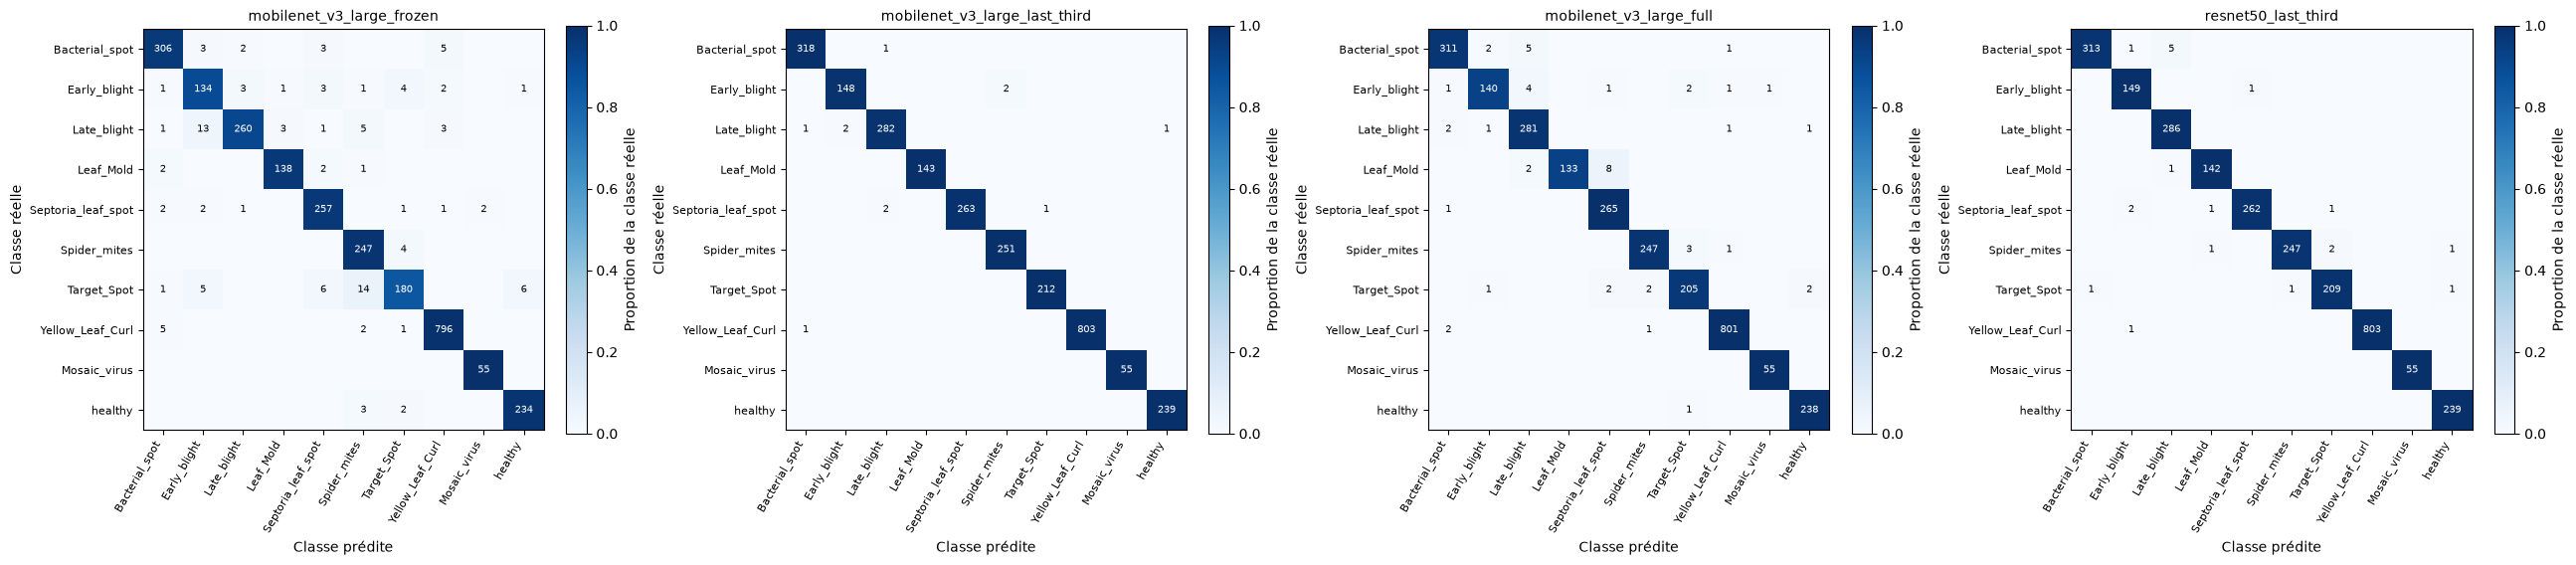

Rappel par classe sur le test :


,mobilenet_v3_large_frozen,mobilenet_v3_large_last_third,mobilenet_v3_large_full,resnet50_last_third
Bacterial_spot,0.959,0.997,0.975,0.981
Early_blight,0.893,0.987,0.933,0.993
Late_blight,0.909,0.986,0.983,1.000
Leaf_Mold,0.965,1.000,0.930,0.993
Septoria_leaf_spot,0.966,0.989,0.996,0.985
Spider_mites,0.984,1.000,0.984,0.984
Target_Spot,0.849,1.000,0.967,0.986
Yellow_Leaf_Curl,0.990,0.999,0.996,0.999
Mosaic_virus,1.000,1.000,1.000,1.000
healthy,0.979,1.000,0.996,1.000


In [68]:
(C.RESULTS / "preds").mkdir(exist_ok=True)
rapports = {}
for nom in modeles:
    model = load_best(modeles[nom], nom)                   # meilleurs poids (validation)
    h = historiques[nom]
    y_vrai, y_pred, proba = predict(model, loaders["test"])
    r = clf_report(y_vrai, y_pred, NOMS)
    rapports[nom] = r

    predictions = pd.DataFrame({"path": loaders["test"].dataset.df["path"], "y_true": y_vrai,
                                "y_pred": y_pred, "msp": proba.max(axis=1)})
    predictions.to_csv(C.RESULTS / "preds" / (nom + "_test.csv"), index=False)

    lr_tete, lr_backbone = LR[model.strategy]
    upsert_summary({"experiment": "P2_" + nom, "partie": 2, "modele": model.arch, "resolution": SIZE,
                    "hyperparametres": model.strategy + ", lr tête " + str(lr_tete) + ", lr backbone " + str(lr_backbone) + ", " + str(EPOCHS) + " époques",
                    "params": count_params(model)[0], "params_entraines": count_params(model)[1],
                    "taille_mo": round(model_size_mb(model), 2), "temps_entrainement_s": round(h["train_time_s"].iloc[-1], 1),
                    "val_f1": round(h["val_f1"].max(), 4), "test_acc": round(r["acc"], 4),
                    "test_f1_macro": round(r["f1_macro"], 4), "run": nom})
    print(nom, ": accuracy", round(r["acc"], 4), "| F1 macro", round(r["f1_macro"], 4))

plt.figure(figsize=(26, 6))
k = 1
for nom in rapports:
    ax = plt.subplot(1, 4, k)
    plot_confusion(rapports[nom]["cm"], NOMS, nom, ax=ax)
    k += 1
plt.tight_layout()
savefig("02_matrices_confusion.png")
plt.show()

rappels = pd.DataFrame()
for nom in rapports:
    rappels[nom] = pd.Series(rapports[nom]["recall"])
print("Rappel par classe sur le test :")
rappels.round(3)

### Temps de réponse (latence)

On mesure le temps qu'il faut pour classer une seule image, comme sur le téléphone. Le modèle est en mode prédiction (`model.eval()`, sans calcul de gradient). On fait d'abord 20 passages qui ne comptent pas, pour « chauffer », puis 100 mesures dont on donne la moyenne et l'écart-type. Sur GPU, on attend la fin du calcul avant et après chaque mesure (`torch.cuda.synchronize()`), sinon on mesurerait seulement son lancement. Sur CPU, on n'utilise qu'un seul cœur, pour se rapprocher d'un téléphone d'entrée de gamme.

Le cours insiste sur le fait que le nombre de paramètres, le nombre de calculs et le temps réel sont trois choses différentes. C'est pour ça qu'on mesure le temps réel plutôt que de compter les paramètres.

- On prend 100 vraies images du test, en 128×128 pour les CNN de la partie 1 et en 224×224 pour les autres.
- On mesure les modèles entraînés, une image à la fois, sur CPU puis sur GPU.
- Le temps dépend du réseau, pas de la stratégie : les 3 versions de MobileNetV3 ont le même.
- On affiche les temps en millisecondes et la machine utilisée.

In [69]:
from src.models import load_classifier

def images_test(taille, norm):

    # 100 vraies images du test
    exemples = D.subset(df, split="test").sample(100, random_state=42)       
    ds = D.LeafDataset(exemples, taille, D.get_transform("clf", False, norm), D.CLASSES, preload=False)
    images = []
    for i in range(len(ds)):
        images.append(ds[i][0])
    return images

# pour les CNN de la partie 1
images_128 = images_test(128, D.norm_stats("scratch"))    

# pour le transfer learning
images_224 = images_test(SIZE, NORM)                         

archis = {"CNN-Plain": (load_classifier(C.CKPT_DIR / "cnn_plain" / "best.pt")[0], images_128),
          "CNN-Res": (load_classifier(C.CKPT_DIR / "cnn_res" / "best.pt")[0], images_128),
          "mobilenet_v3_large": (modeles["mobilenet_v3_large_" + MEILLEURE], images_224),
          "resnet50": (modeles[nom_lourd], images_224)}

latence = {}
for nom in archis:
    model, images = archis[nom]
    taille = images[0].shape[-1]
    cpu_moy, cpu_std = measure_latency(model, taille, "cpu", threads=1, images=images)
    if torch.cuda.is_available():
        gpu_moy, gpu_std = measure_latency(model, taille, "cuda", images=images)
    else:
        gpu_moy, gpu_std = float("nan"), float("nan")
    latence[nom] = {"cpu_ms": cpu_moy, "cpu_std": cpu_std, "gpu_ms": gpu_moy, "gpu_std": gpu_std}
    print(nom, ": CPU", round(cpu_moy, 1), "±", round(cpu_std, 1), "ms | GPU", round(gpu_moy, 2), "±", round(gpu_std, 2), "ms")

if torch.cuda.is_available():
    gpu = torch.cuda.get_device_name(0)
else:
    gpu = "aucun"
machine = "CPU : " + C.cpu_name() + " (1 thread), GPU : " + gpu
print(machine)
C.save_json({"machine": machine, "latence": latence}, C.RESULTS / "latency.json")

CNN-Plain : CPU 22.0 ± 5.0 ms | GPU 2.12 ± 1.27 ms
CNN-Res : CPU 62.4 ± 6.5 ms | GPU 0.89 ± 0.29 ms
mobilenet_v3_large : CPU 13.4 ± 2.7 ms | GPU 5.21 ± 1.54 ms
resnet50 : CPU 111.4 ± 15.2 ms | GPU 6.63 ± 2.08 ms
CPU : 13th Gen Intel(R) Core(TM) i7-13650HX (1 thread), GPU : NVIDIA GeForce RTX 4080 Laptop GPU


- On ajoute le temps de chaque modèle dans `summary.csv`, y compris pour les deux CNN de la partie 1.
- Le tableau regroupe tous les chiffres demandés : paramètres, taille, temps CPU et GPU, accuracy, F1 macro.

In [70]:
# chaque expérience et l'architecture dont elle utilise la latence
experiences = {"P1_CNN-Plain": "CNN-Plain", "P1_CNN-Res": "CNN-Res"}
for nom in modeles:
    if nom.startswith("mobilenet"):
        experiences["P2_" + nom] = "mobilenet_v3_large"
    else:
        experiences["P2_" + nom] = "resnet50"

for exp in experiences:
    archi = experiences[exp]
    resume = update_summary(exp, latence_cpu_ms=round(latence[archi]["cpu_ms"], 2),
                            latence_gpu_ms=round(latence[archi]["gpu_ms"], 3))

pareto = resume[resume["experiment"].isin(list(experiences))].reset_index(drop=True)
pareto[["experiment", "params", "taille_mo", "latence_cpu_ms", "latence_gpu_ms", "val_f1", "test_acc", "test_f1_macro"]]

,experiment,params,taille_mo,latence_cpu_ms,latence_gpu_ms,val_f1,test_acc,test_f1_macro
0,P1_CNN-Plain,1336458.0,5.36,22.05,2.119,0.9705,0.9703,0.9612
1,P1_CNN-Res,1190922.0,4.79,62.41,0.886,0.9738,0.9717,0.9660
2,P2_mobilenet_v3_large_frozen,4214842.0,17.07,13.44,5.208,0.9537,0.9567,0.9479
3,P2_mobilenet_v3_large_last_third,4214842.0,17.07,13.44,5.208,0.9916,0.9960,0.9955
4,P2_mobilenet_v3_large_full,4214842.0,17.07,13.44,5.208,0.9721,0.9820,0.9778
5,P2_resnet50_last_third,23528522.0,94.44,111.36,6.625,0.9904,0.9927,0.9913


## 2.4 Front de Pareto

Un modèle est « dominé » si un autre modèle est à la fois plus rapide et plus précis. Les modèles qui ne sont dominés par aucun autre forment le front de Pareto (en rouge). L'axe du temps est en échelle log. Comme le dit le cours à propos de MobileNet, il n'y a pas un seul « meilleur » modèle dans l'absolu : le bon choix dépend du temps qu'on peut se permettre.

- Pour chaque modèle, on prend son temps sur CPU (x) et son F1 macro (y).
- Double boucle : un modèle est dominé si un autre est au moins aussi rapide et plus précis. Les autres sont sur le front et s'affichent en rouge.
- On trace le nuage de points avec le nom de chaque modèle.

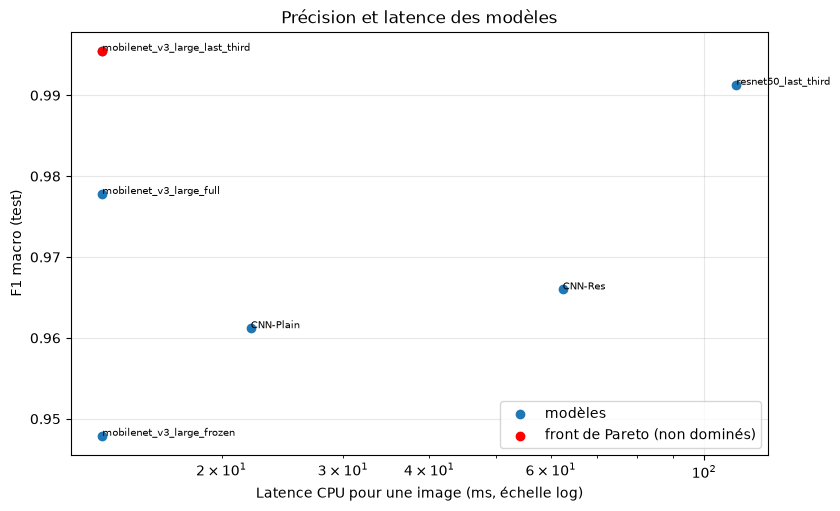

Modèles sur le front de Pareto : ['mobilenet_v3_large_last_third']


In [71]:
x = pareto["latence_cpu_ms"].astype(float).values
y = pareto["test_f1_macro"].astype(float).values
noms = pareto["experiment"].str.replace("P1_", "").str.replace("P2_", "").values

# Un modèle est dominé si un autre modèle est au moins aussi rapide ET plus précis
non_domines = []
for i in range(len(x)):
    domine = False
    for j in range(len(x)):
        if x[j] <= x[i] and y[j] > y[i]:
            domine = True
    if not domine:
        non_domines.append(i)

plt.figure(figsize=(9, 5.5))
plt.scatter(x, y, label="modèles")
plt.scatter(x[non_domines], y[non_domines], color="red", label="front de Pareto (non dominés)")
for i in range(len(x)):
    plt.annotate(noms[i], (x[i], y[i]), fontsize=7)
plt.xscale("log")
plt.xlabel("Latence CPU pour une image (ms, échelle log)")
plt.ylabel("F1 macro (test)")
plt.title("Précision et latence des modèles")
plt.legend()
plt.grid(alpha=0.3)
savefig("02_pareto.png")
plt.show()
print("Modèles sur le front de Pareto :", list(noms[non_domines]))

## 2.5 Recommandation

- On choisit la version de MobileNetV3 qui a le meilleur F1 de validation.
- On la compare chiffre par chiffre à ResNet-50 et on enregistre ce choix dans `results/recommendation.json`, relu par les notebooks 04 et 06.

In [72]:
# on choisit parmi les MobileNet celui qui a le meilleur F1 de VALIDATION
choix = None
for i in range(len(pareto)):
    ligne = pareto.iloc[i]
    if ligne["experiment"].startswith("P2_mobilenet"):
        if choix is None or float(ligne["val_f1"]) > float(choix["val_f1"]):
            choix = ligne
lourd = pareto[pareto["experiment"] == "P2_" + nom_lourd].iloc[0]

C.save_json({"run": choix["run"], "arch": "mobilenet_v3_large", "strategy": MEILLEURE, "size": SIZE},
            C.RESULTS / "recommendation.json")
print("Modèle recommandé :", choix["run"])
print("  F1 test", round(float(choix["test_f1_macro"]), 4), "contre", round(float(lourd["test_f1_macro"]), 4), "pour ResNet-50")
print("  latence CPU", round(float(choix["latence_cpu_ms"]), 1), "ms contre", round(float(lourd["latence_cpu_ms"]), 1), "ms")
print("  taille", round(float(choix["taille_mo"]), 1), "Mo contre", round(float(lourd["taille_mo"]), 1), "Mo")

Modèle recommandé : mobilenet_v3_large_last_third
  F1 test 0.9955 contre 0.9913 pour ResNet-50
  latence CPU 13.4 ms contre 111.4 ms
  taille 17.1 Mo contre 94.4 Mo


### Notre recommandation

Pour un smartphone d'entrée de gamme qui doit marcher sans connexion, nous recommandons MobileNetV3-Large avec le dernier tiers dégelé.

C'est le plus précis de tous nos modèles, avec 0,9955 de F1 macro sur le test, devant ResNet-50 (0,9913). Il est aussi environ 8 fois plus rapide sur un cœur de CPU (13,4 ms par image contre 111,4 ms) et 5,5 fois plus petit (17,1 Mo contre 94,4 Mo). C'est le seul modèle sur le front de Pareto : il bat tous les autres, y compris nos CNN entraînés de zéro (CNN-Plain : 22,0 ms et 0,961 de F1, CNN-Res : 62,4 ms et 0,966). Et sa taille peut encore être divisée par environ 4 en passant ses poids en 8 bits (bonus, notebook 07).

Nos mesures illustrent bien l'idée du cours selon laquelle paramètres, calculs et temps réel sont trois choses différentes. CNN-Res a 3,5 fois moins de paramètres que MobileNetV3 (1,19 M contre 4,21 M), et pourtant il est environ 4,7 fois plus lent sur CPU. Ses convolutions de 64 à 256 filtres travaillent sur de grandes images (128 × 128) et demandent environ 2,5 milliards de multiplications par image, contre environ 0,2 milliard pour MobileNetV3 grâce à ses convolutions séparables.

Sur GPU, l'avance de MobileNetV3 disparaît presque : 5,2 ms contre 6,6 ms pour ResNet-50, des valeurs proches vu les écarts-types (1,5 à 2 ms), alors que ResNet-50 fait environ 20 fois plus de calculs. Lors d'une première mesure, MobileNetV3 était même plus lent (7,6 ms contre 5,2 ms). D'après le cours, ses convolutions séparables utilisent mal un GPU. En plus, quand on traite une seule image, le temps vient surtout du lancement de ses nombreuses petites couches. Mais le téléphone visé n'a pas ce genre de GPU : c'est le temps sur CPU qui compte pour notre choix.

Les temps varient un peu d'une exécution à l'autre (ResNet-50 sur CPU : 121 ms, 114 ms puis 111 ms), car sur un PC portable la vitesse du processeur change avec le mode turbo et la chauffe. Les ordres de grandeur, eux, ne bougent pas.

Enfin, des scores de 99,5 % doivent nous rendre méfiants. Les images de test viennent du même laboratoire, avec le même fond gris. La partie 6 vérifie si le modèle regarde vraiment la maladie ou s'il s'aide du fond.

## Classifieur sans la maladie M (pour la partie 4)

On retire complètement la mosaïque (la maladie M) du train et de la validation, puis on réentraîne le modèle recommandé sur les 9 classes restantes. Les images de mosaïque du test joueront le rôle d'images « inconnues » dans la partie 4.

- On garde seulement les 9 classes connues et on vérifie que la mosaïque n'est pas dans le train.
- Même réseau et même stratégie que le modèle recommandé.
- On affiche les courbes et on copie les meilleurs poids dans `results/ckpt/clf_sans_M.pt`. Le test sera fait dans la partie 4.

Reprise depuis l'époque 5


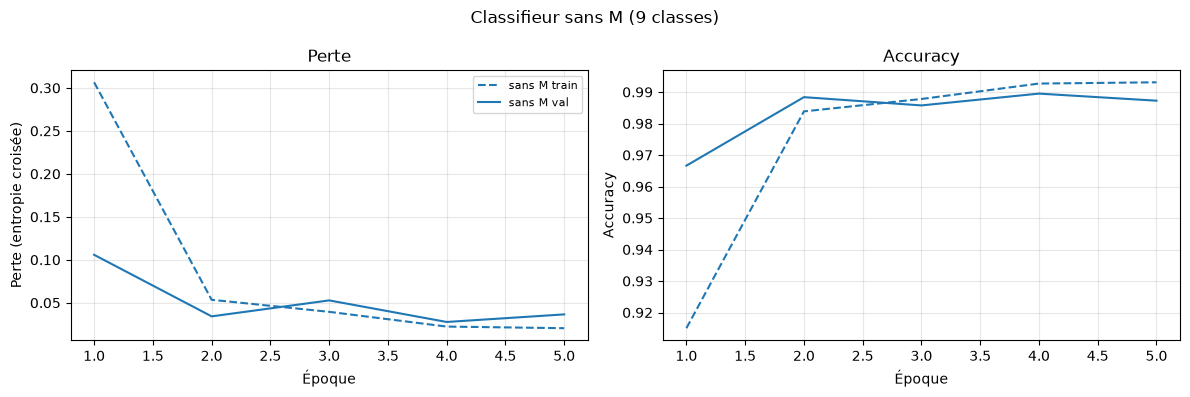

Classifieur sans M enregistré : results/ckpt/clf_sans_M.pt
Meilleur F1 de validation (9 classes) : 0.987


In [73]:
CONNUES = D.KNOWN_CLASSES                    # les 9 classes sans la mosaïque
loaders9 = D.clf_loaders(df, CONNUES, SIZE, NORM, batch_size=64)
assert C.UNKNOWN_CLASS not in set(loaders9["train"].dataset.df["class"])

poids9 = D.class_weights(loaders9["train"].dataset.labels, len(CONNUES)).to(C.DEVICE)
criterion9 = nn.CrossEntropyLoss(weight=poids9)
model9, h9 = entrainer_tl("clf_sans_M", "mobilenet_v3_large", MEILLEURE, CONNUES, loaders9, criterion9)

plot_histories({"sans M": h9}, path=C.FIG_DIR / "02_clf_sans_M.png", title="Classifieur sans M (9 classes)")
export_checkpoint("clf_sans_M", "clf_sans_M.pt")
print("Classifieur sans M enregistré : results/ckpt/clf_sans_M.pt")
print("Meilleur F1 de validation (9 classes) :", round(h9["val_f1"].max(), 4))